<a href="https://colab.research.google.com/github/ibrahimshkhess/smart-air-quality-lighting-iot/blob/main/AirModelPrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AirModelPrediction

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



# Library setting



In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from sklearn.preprocessing import StandardScaler
import os
import random
import keras


Seeting the seeds:

In [3]:
# fix random seed for reproducibility
def set_all_seeds(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'

set_all_seeds(42)
np.random.seed(42) #it also fix the seed for sklearn

# Inizialization of Input Data

In [4]:
driver_path='/content/drive/MyDrive/AirQualityPrediction/'

In [5]:
air_quality_raw = pd.read_csv(driver_path+'air_mesurament_adjusted.csv', header=None, index_col=False, sep=';', engine='python')

In [6]:
air_quality_df =air_quality_raw.drop(0, axis=0)
cols_data = air_quality_df.columns[0:3]
air_quality_df[cols_data] = air_quality_df[cols_data].apply(pd.to_numeric, errors='coerce')
col_timestamp  = air_quality_df.columns[3]
air_quality_df[col_timestamp] = pd.to_datetime(
    air_quality_df[col_timestamp],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)
air_quality_df = air_quality_df.dropna(axis=0)
print(air_quality_df.head(), air_quality_df.shape)

         0        1        2                   3
1  397.163  419.985  419.985 2022-10-27 10:55:00
2  396.138  418.902  418.902 2022-10-27 10:55:00
3  397.071  419.888  419.888 2022-10-27 10:55:00
4  397.071  419.888  419.888 2022-10-27 10:55:00
5  397.071  419.888  419.888 2022-10-27 10:55:00 (1048572, 4)


Comprime the dateset taking the average value for each minute

In [7]:
air_quality_df_avg = air_quality_df.groupby(3, as_index=False)[[0, 1, 2]].mean()

In [8]:
air_quality_df_avg.tail(1)

,3,0,1,2
38491,2022-11-24 00:21:00,265.596,280.858,280.858


Reorder the columns to match your original [pm1, pm10, pm25, timestamp] layout

In [9]:
air_quality_df_avg = air_quality_df_avg[[0, 2, 1, 3]]

In [10]:
air_quality_df_avg.tail(1)

,0,2,1,3
38491,265.596,280.858,280.858,2022-11-24 00:21:00


In [11]:
N= len(air_quality_df_avg)
train_end = int(N * 0.70)
val_end = int(N * 0.85)

value scaled

In [12]:
scaler = StandardScaler()
scaler.fit(air_quality_df_avg.iloc[:train_end, 0:3])

StandardScaler()

In [13]:
air_quality_df_scale = air_quality_df_avg.copy()
air_quality_df_scale.iloc[:, 0:3] = scaler.transform(air_quality_df_avg.iloc[:, 0:3])

In [14]:
air_quality_df_scale.tail(1)

,0,2,1,3
38491,0.114892,0.107109,0.109715,2022-11-24 00:21:00


# Prediction Sequence Model

now the idea is take the the average of the first five minute and predict the value after 10 min

In [15]:
NUM_SENSOR = 1
feaature_Pm=3
n_db=1 #consider 1 datebase with the same feature
num_features = NUM_SENSOR * feaature_Pm*n_db

In [16]:
look_back_minutes = 5
predict_ahead_minutes = 10

In [17]:
def create_timeseries_dataset(df,num_features, look_back=5, forecast_horizon=10):
    # Extract just the numerical features (columns 0, 1, 2) as a NumPy array for speed
    features = df.iloc[:, 0:3].values
    # Calculate the maximum index we can reach without going out of bounds
    max_index = len(features) - look_back - forecast_horizon

    X_reshaped = np.zeros((max_index, look_back, num_features))
    Y_reshaped = np.zeros((max_index, num_features))


    for i in range(max_index):
        # 1. Grab the window of 'look_back' minutes (e.g., indices 0 to 4)
        window = features[i : i + look_back]

        X_reshaped[i]= window.reshape(look_back, num_features)
        target_index = i + look_back + forecast_horizon - 1
        target = features[target_index]
        Y_reshaped[i]=target

    return X_reshaped,Y_reshaped

In [18]:

X, y = create_timeseries_dataset(
      df=air_quality_df_scale,
      num_features=num_features,
      look_back=look_back_minutes,
      forecast_horizon=predict_ahead_minutes
)

print(f"X shape: {X.shape}") # Should be (number_of_samples, 5, 3)
print(f"y shape: {y.shape}") # Should be (number_of_samples, 3)

X shape: (38477, 5, 3)
y shape: (38477, 3)


In [19]:

trainX=X[:train_end]
testX=X[train_end:val_end]
valX=X[val_end:]

trainY=y[:train_end]
testY=y[train_end:val_end]
valY=y[val_end:]

In [20]:
valX.shape

(5759, 5, 3)

In [21]:
valY.shape

(5759, 3)

train model

In [85]:
epochs= 32
batchs_size=96

In [86]:
model = tf.keras.Sequential([
    # Use a standard, forward-only LSTM with fewer units
    tf.keras.layers.LSTM(32, return_sequences=False, input_shape=(look_back_minutes, num_features),dropout=0.1),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(num_features)
])

# Compile using Mean Squared Error
model.compile(
    loss=tf.keras.losses.MeanSquaredError(),
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    metrics=[tf.keras.metrics.MeanAbsoluteError()] # Use MAE to track average error
)

# Train the model
history = model.fit(
    x=trainX, y=trainY,
    epochs=epochs,
    batch_size=batchs_size, # Batch size helps memory management and gradient calculation
    validation_data=(valX, valY)
)
trainPredict = model.predict(trainX)

Epoch 1/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.7784 - mean_absolute_error: 0.6793 - val_loss: 1.0950 - val_mean_absolute_error: 0.9469
Epoch 2/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.3130 - mean_absolute_error: 0.3924 - val_loss: 0.2821 - val_mean_absolute_error: 0.4559
Epoch 3/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.2137 - mean_absolute_error: 0.3168 - val_loss: 0.1670 - val_mean_absolute_error: 0.3405
Epoch 4/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2055 - mean_absolute_error: 0.3079 - val_loss: 0.1483 - val_mean_absolute_error: 0.3106
Epoch 5/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2009 - mean_absolute_error: 0.3026 - val_loss: 0.1414 - val_mean_absolute_error: 0.2970
Epoch 6/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1996 - mean_absolute_error: 0.2981 - val_loss: 0.1371 - val_mean_absolute_error: 0.2876
Epoch 7/32
281/281 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1966 - mean_absolute_error: 0.2957 -

Save model

In [87]:
driver_path='/content/drive/MyDrive/AirQualityPrediction/'

In [88]:
model.save(driver_path+'model_dense.keras')

Load the model

In [89]:
driver_path='/content/drive/MyDrive/AirQualityPrediction/'

In [90]:
model = keras.models.load_model(driver_path+'model_dense.keras')


In [91]:
test_loss, test_acc = model.evaluate(testX,testY)

print('Test Loss:', test_loss)
print('Test MeanAbsoluteError:', test_acc)

181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1788 - mean_absolute_error: 0.2915
Test Loss: 0.17878425121307373
Test MeanAbsoluteError: 0.29150301218032837


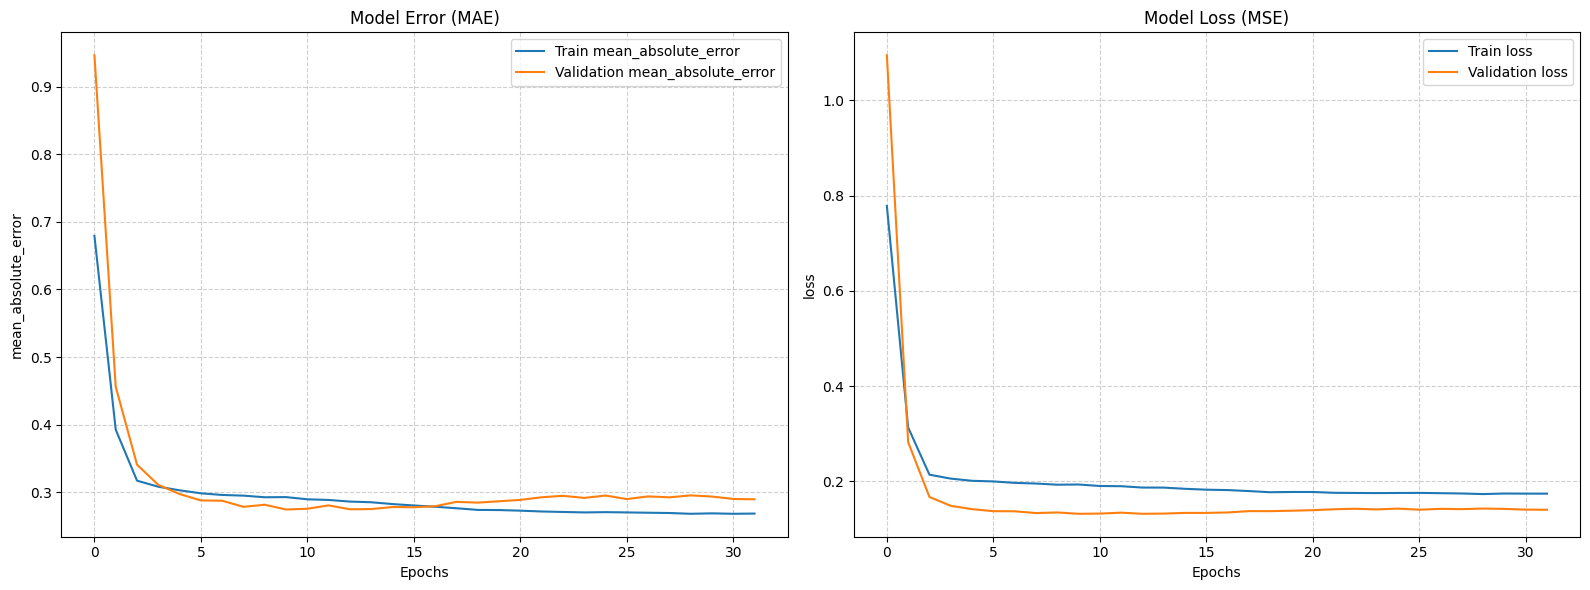

In [92]:

def plot_graphs(history, metric, title):
    # Pass labels directly to the plot function for a cleaner legend
    plt.plot(history.history[metric], label=f'Train {metric}')
    plt.plot(history.history['val_' + metric], label=f'Validation {metric}')
    plt.xlabel("Epochs")
    plt.ylabel(metric)
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6) # Adding a grid helps read continuous metrics

plt.figure(figsize=(16, 6))

# Subplot 1: Mean Absolute Error (Replaces Accuracy)
plt.subplot(1, 2, 1)
# Keras usually tracks MAE as 'mean_absolute_error' or 'mae' depending on the exact string used
metric_name = 'mean_absolute_error' if 'mean_absolute_error' in history.history else 'mae'
plot_graphs(history, metric_name, 'Model Error (MAE)')

# Subplot 2: Loss (Mean Squared Error)
plt.subplot(1, 2, 2)
plot_graphs(history, 'loss', 'Model Loss (MSE)')

# Optional: If your initial error is incredibly high and drops fast,
# the graph will look like an "L" shape. Uncommenting the line below
# puts the Y-axis on a log scale so you can see the fine details of the training curve.
# plt.yscale('log')

plt.tight_layout()
plt.savefig('training_curves.png') # Good practice to save the plot!
plt.show()

In [93]:
predictions= model.predict(testX)
predictions=scaler.inverse_transform(predictions)
testY_v=scaler.inverse_transform(testY)

181/181 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


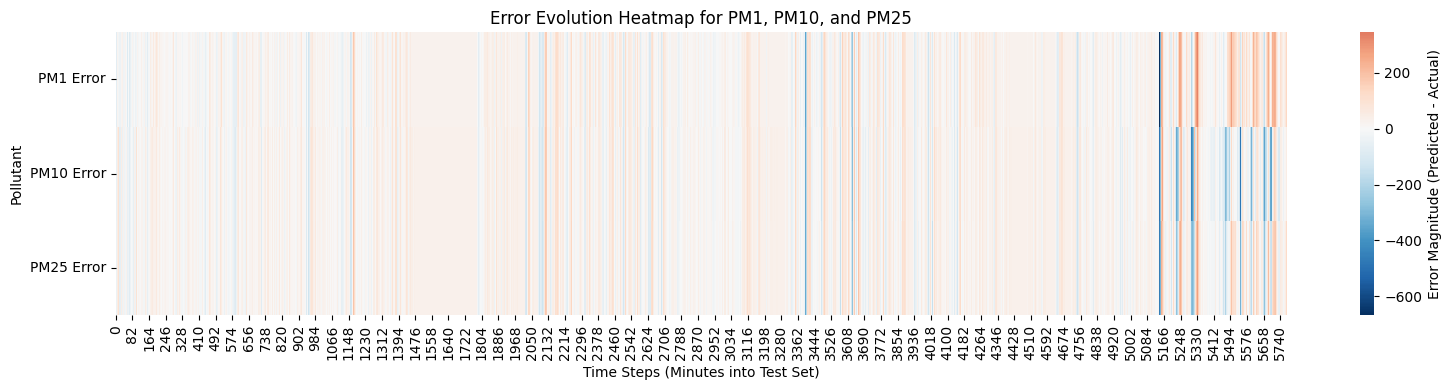

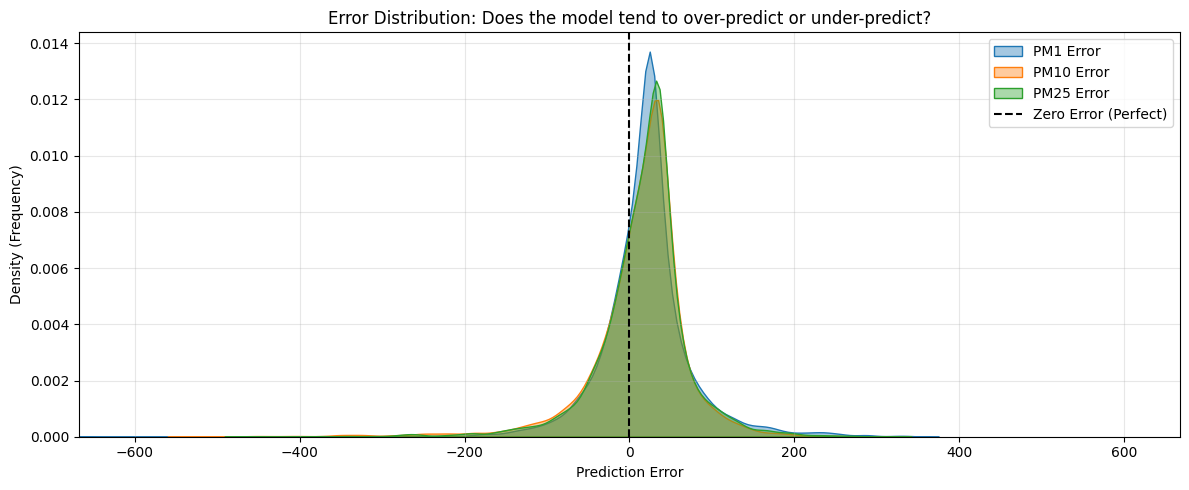

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate the raw error for all 3 values (Predicted - Actual)
errors = predictions - testY_v

# Create a DataFrame for Seaborn
error_df = pd.DataFrame(errors, columns=['PM1 Error', 'PM10 Error', 'PM25 Error'])

# =====================================================================
# PLOT 1: The Error Heatmap (Evolution Over Time)
# =====================================================================
plt.figure(figsize=(16, 4))

# Transpose (.T) so time is on the X-axis and the 3 pollutants are on the Y-axis
# cmap="RdBu_r" creates a Red (Positive/Over) to Blue (Negative/Under) color scale centered at 0
sns.heatmap(error_df.T, cmap="RdBu_r", center=0,
            cbar_kws={'label': 'Error Magnitude (Predicted - Actual)'})

plt.title('Error Evolution Heatmap for PM1, PM10, and PM25')
plt.xlabel('Time Steps (Minutes into Test Set)')
plt.ylabel('Pollutant')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# =====================================================================
# PLOT 2: Error Distribution (Overall Bias for the 3 values)
# =====================================================================
plt.figure(figsize=(12, 5))

# Plot a density curve for each of the 3 pollutants
for col in error_df.columns:
    sns.kdeplot(error_df[col], label=col, fill=True, alpha=0.4)

plt.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error (Perfect)')
plt.title('Error Distribution: Does the model tend to over-predict or under-predict?')
plt.xlabel('Prediction Error')
plt.ylabel('Density (Frequency)')
plt.legend()
plt.xlim(-max(abs(errors.flatten())), max(abs(errors.flatten()))) # Keep the X-axis symmetrical
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()